### rc_test2_silo

Using the more optimised ESN implementation in 'optimised_rc' on actual data sourced from  
the SILO Dataset 
- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1  

-- Methods inside of ESN class have also been improved
-- Additional methods to apply and plot ESN developed 

--- Date:   April 2026

In [ ]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [ ]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')
    
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass
    
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    - extract rain and gddc vectors
    """
    clean = clean_data(df)
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()
    clean_rain = clean[['Rain.Mean']].values
    clean_gddc = clean[['GDD.C']].values
    return clean_rain, clean_gddc

In [31]:
#Brunswick Junction (9513) - (Kwinana West Port Zone)
brunswick_data = collect_data('standard','-33.21','115.85','20010101','20260327','email@gmail.com')
brunswick_rain, brunswick_gddc = prepare_data(brunswick_data)

#Northam (10111) - Kwinana East Port Zone
northam_data = collect_data('standard','-31.65','116.66','20010101','20260327','email@gmail.com')
northam_rain, northam_gddc = prepare_data(northam_data)

# Northampton (8100) - Geraldton Port Zone
nh_data = collect_data('standard','-28.36','114.63','20010101','20260327','email@gmail.com')
nh_rain, nh_gddc = prepare_data(nh_data)

# Esperance (9789) - Esperance Port Zone
esperance_data = collect_data('standard','-33.83','121.89','20010101','20260327','email@gmail.com')
esperance_rain, esperance_gddc = prepare_data(esperance_data)

# Albany (9500) - Albany Port Zone
albany_data = collect_data('standard','-35.03','117.88','20010101','20260327','email@gmail.com')
albany_rain, albany_gddc = prepare_data(albany_data)


In [ ]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    split: proportion of data to take as training  
    """
    def __init__(self, N, d, rho):
        self.N = N
        self.d = d
        self.rho = rho

        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N))) 

        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = np.random.uniform(-1,1,size=(self.N,1))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(self.N,))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        """
        states = np.zeros((len(input_data), self.N))
        for i in range(1, len(input_data)):
            # feed previous state through the weights with the input and bias
            # use sigmoidal tanh to condense values
            states[i, :] = np.tanh(np.matmul(self.Vadj, states[i-1, :]) + np.matmul(self.Vin,input_data[i]) + self.Vbias)
        return states        

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        train_states = train_states[washout:]
        train_target = train_target[washout:]
        N, t = np.shape(train_states.T)

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(np.dot(train_target.T,train_states), 
                           np.linalg.pinv(np.dot(train_states.T, train_states)+ beta*np.identity(N)))


    def predict(self, test_input, washout):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)
        test_states[washout:]
        test_input[washout:]

        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout.T)

        # compute RMSE of predictions
        rmse = np.sqrt(((predictions - test_input)**2).mean())

        return predictions, rmse
    


In [ ]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size]
    train_target = rain[step:train_size+step]
    test_target = rain[train_size+step:]
    x_values = gddc[train_size+step:]

    return train_input, train_target, test_target, x_values


def plotting_data(x_values, test_actual, test_predictions, title):
    """
    function to plot the resulting predictions against the actual data
    """
    plt.plot(x_values,test_actual, label = 'actual_values',color='green',)
    plt.plot(x_values, test_predictions, label='predicted',color='red',alpha=0.6)
    plt.xlabel('GDD.C')
    plt.ylabel('Rain')
    plt.title(title)
    plt.legend()
    plt.show()

def rc_for_location(location, rain, gddc, step, nodes=100, connections=5, rho=0.9):
    """
    function to generate predictions for a particular given location and step size
    """
    # split the input data into testing and target input
    train_input, train_target, test_target, x_vals = splitting_data(rain, gddc, step)
    # create the Echo State Network
    esn = ESN(nodes,connections,rho)
    # train the ESN
    esn.train(train_input, train_target, washout=100)
    # generate predictions and RMSE 
    rain_pred, rmse = esn.predict(test_target, washout=100)
    # plot the data
    plotting_data(x_vals, test_target, rain_pred, title=location+" "+str(step)+" steps")

    return rmse

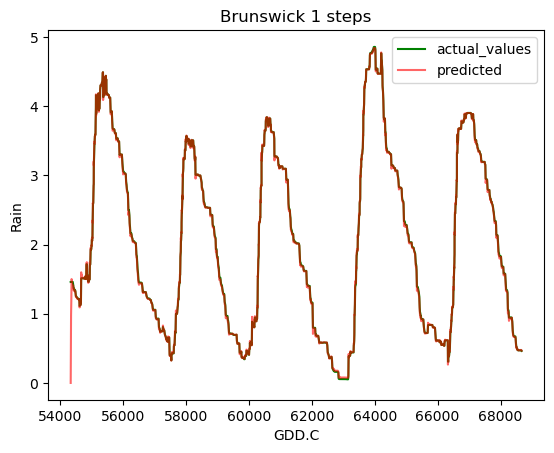

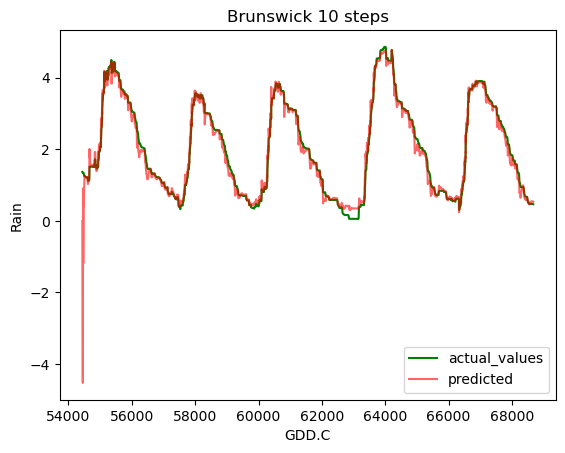

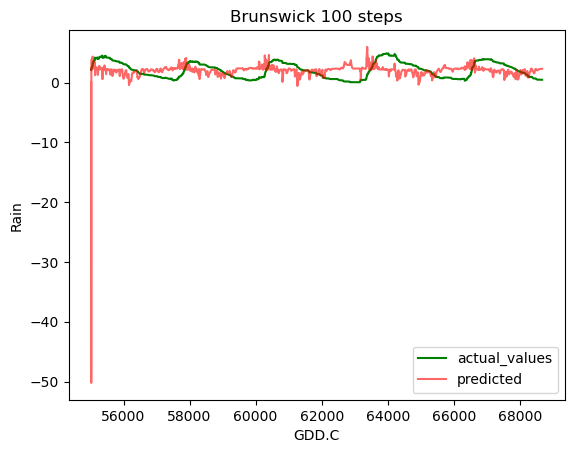

In [34]:
brun_rmse_1step = rc_for_location('Brunswick', brunswick_rain, brunswick_gddc, step=1)
brun_rmse_10step = rc_for_location('Brunswick', brunswick_rain, brunswick_gddc, step=10)
brun_rmse_100step = rc_for_location('Brunswick', brunswick_rain, brunswick_gddc, step=100)

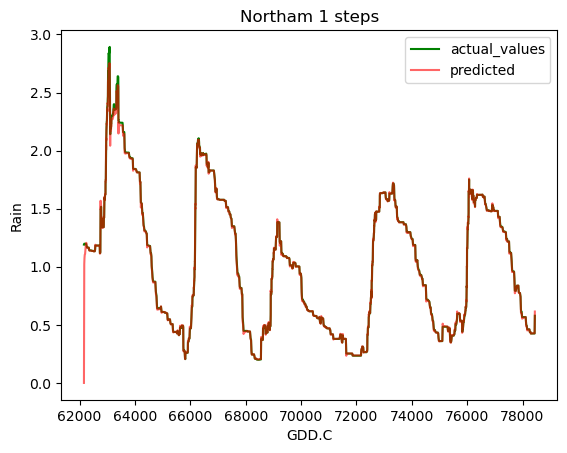

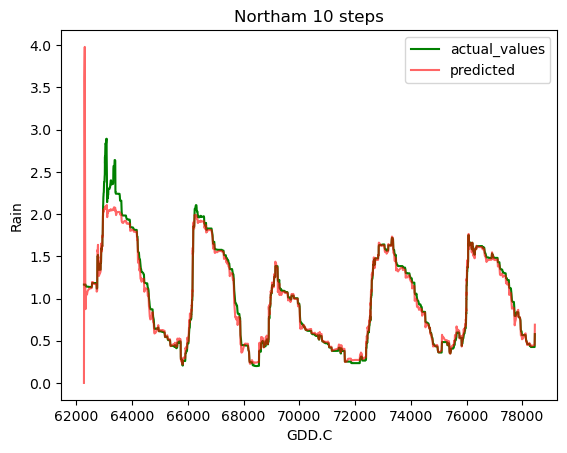

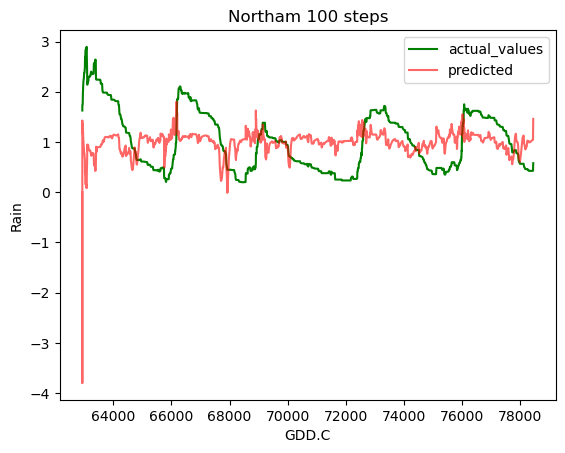

In [35]:
nor_rmse_1step = rc_for_location('Northam', northam_rain, northam_gddc, step=1)
nor_rmse_10step = rc_for_location('Northam', northam_rain, northam_gddc, step=10)
nor_rmse_100step = rc_for_location('Northam', northam_rain, northam_gddc, step=100)


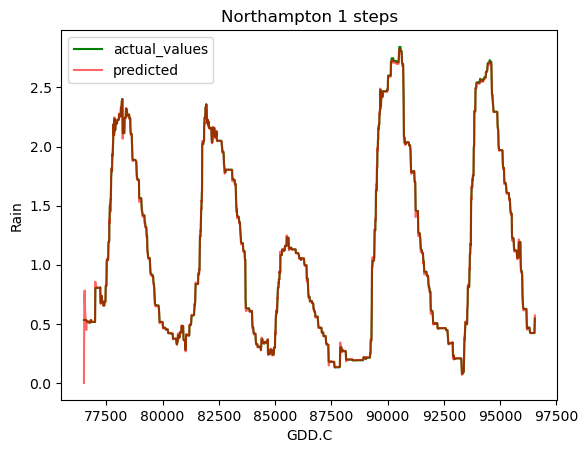

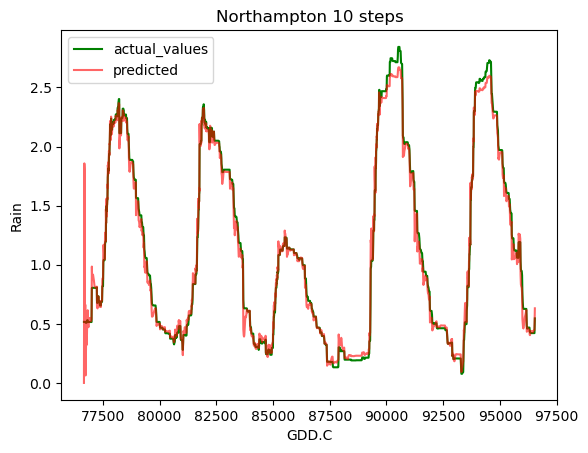

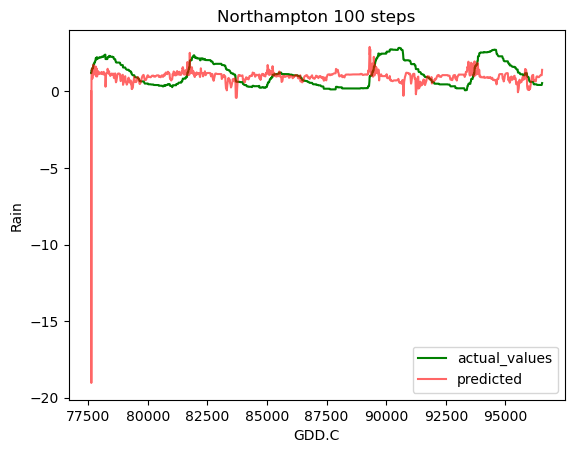

In [36]:
nh_rmse_1step = rc_for_location('Northampton', nh_rain, nh_gddc, step=1)
nh_rmse_10step = rc_for_location('Northampton', nh_rain, nh_gddc, step=10)
nh_rmse_100step = rc_for_location('Northampton', nh_rain, nh_gddc, step=100)


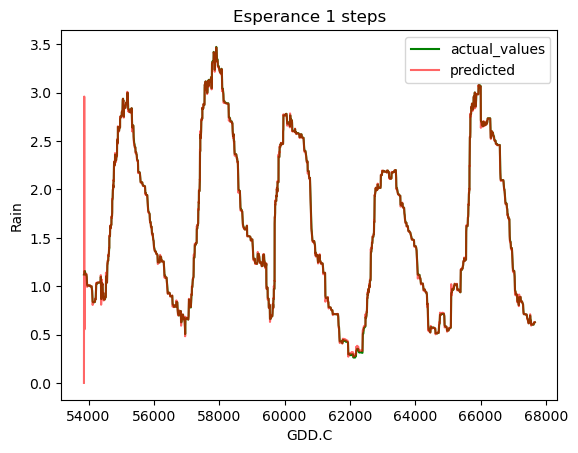

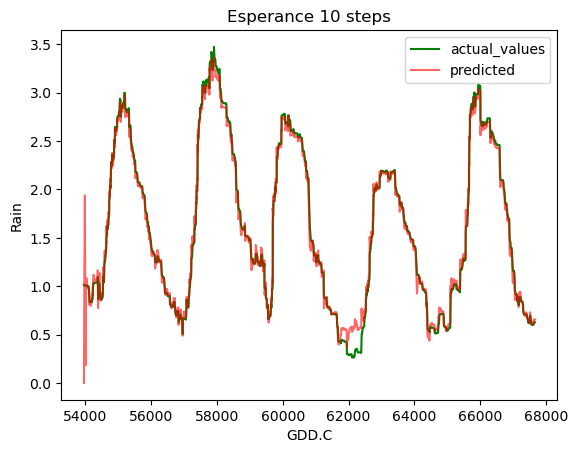

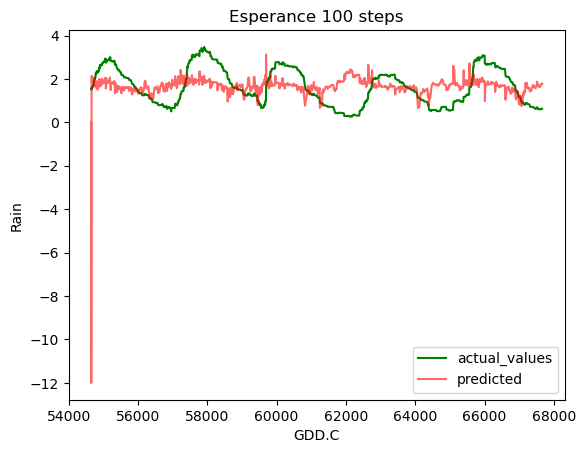

In [37]:
esp_rmse_1step = rc_for_location('Esperance', esperance_rain, esperance_gddc, step=1)
esp_rmse_10step = rc_for_location('Esperance', esperance_rain, esperance_gddc, step=10)
esp_rmse_100step = rc_for_location('Esperance', esperance_rain, esperance_gddc, step=100)


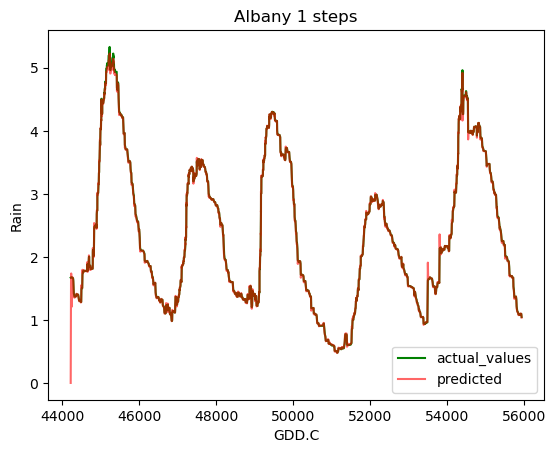

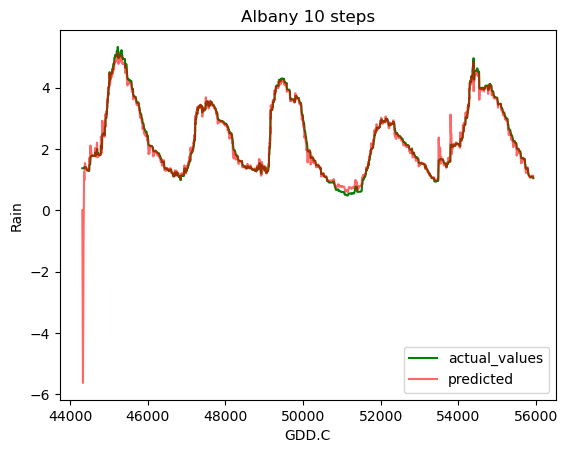

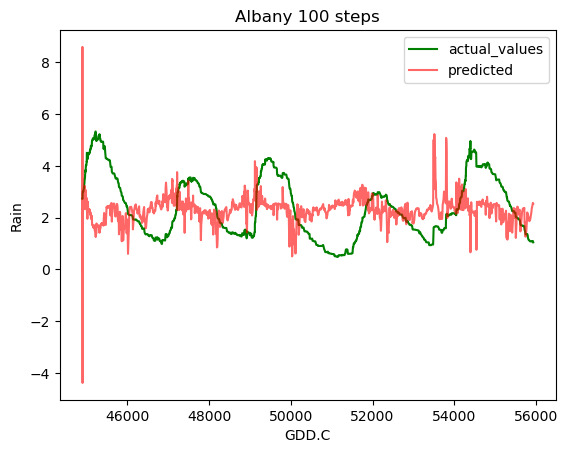

In [38]:
alb_rmse_1step = rc_for_location('Albany', albany_rain, albany_gddc, step=1)
alb_rmse_10step = rc_for_location('Albany', albany_rain, albany_gddc, step=10)
alb_rmse_100step = rc_for_location('Albany', albany_rain, albany_gddc, step=100)

In [39]:
rmse = {
    'Location': ['Brunswick','Northam', 'Northampton','Esperance', 'Albany'],
    '1 Step': [brun_rmse_1step, nor_rmse_1step, nh_rmse_1step, esp_rmse_1step, alb_rmse_1step],
    '10 Step': [brun_rmse_10step, nor_rmse_10step, nh_rmse_10step, esp_rmse_10step, alb_rmse_10step],
    '100 Step': [brun_rmse_100step, nor_rmse_100step, nh_rmse_100step, esp_rmse_100step, alb_rmse_100step]
}

rmse_df = pd.DataFrame(data=rmse)
rmse_df

,Location,1 Step,10 Step,100 Step
0,Brunswick,0.040331,0.199742,2.216478
1,Northam,0.034041,0.157063,0.738461
2,Northampton,0.017536,0.076850,1.170490
3,Esperance,0.053123,0.079335,0.965238
4,Albany,0.045895,0.233881,1.430291
